# Day 9: Vector Representation & Cosine Similarity
Semantic similarity workflow with TF-IDF + cosine similarity.

## 1. Why plain text can't be compared directly
Computers only operate on numbers. The strings `"king"` and `"queen"` are just different sequences of characters, so string equality or character overlap says nothing about meaning. To compare text mathematically we convert each text into a **numerical vector**, where each dimension captures some feature (here, a weighted word count). Once text is a vector, we can use linear algebra to measure how related two pieces of text are, search, cluster and classify them.

**TF-IDF** weights each word by how often it appears in a document (TF) and down-weights words common across all documents (IDF), so distinctive words matter more than words like "the".

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

corpus = [
    # Topic 1: animals
    "The dog barked at the mailman",
    "A puppy is a young dog that loves to play",
    "Cats and dogs are popular pets",
    # Topic 2: aviation
    "The airplane landed at the airport",
    "Pilots fly the airplane across the ocean",
    "The airport was busy with flights and airplane traffic",
    # Topic 3: cooking
    "She cooked pasta with tomato sauce",
    "Bake the bread in a hot oven",
    "The chef cooked a delicious tomato soup",
    "Cooking pasta takes ten minutes in boiling water",
]
vec = TfidfVectorizer(stop_words='english')
X = vec.fit_transform(corpus)
print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (10, 36)


In [2]:
sim = cosine_similarity(X)          # NumPy 10x10 matrix
print(type(sim), sim.shape)
np.set_printoptions(precision=2, suppress=True)
print(sim)

<class 'numpy.ndarray'> (10, 10)
[[1.   0.2  0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.2  1.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   1.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   1.   0.19 0.41 0.   0.   0.   0.  ]
 [0.   0.   0.   0.19 1.   0.14 0.   0.   0.   0.  ]
 [0.   0.   0.   0.41 0.14 1.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   1.   0.   0.39 0.17]
 [0.   0.   0.   0.   0.   0.   0.   1.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.39 0.   1.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.17 0.   0.   1.  ]]


In [3]:
def find_similar(query, corpus, top_k=3):
    vec = TfidfVectorizer(stop_words='english')
    X = vec.fit_transform(corpus + [query])
    scores = cosine_similarity(X[-1], X[:-1]).flatten()
    idx = np.argsort(scores)[::-1][:top_k]
    return [(corpus[i], round(float(scores[i]), 3)) for i in idx]

for q in ["A puppy plays with the dog", "The plane took off from the airport", "I am cooking tomato pasta"]:
    print("\nQuery:", q)
    for s, sc in find_similar(q, corpus, 3): print(f"  {sc:.3f}  {s}")


Query: A puppy plays with the dog
  0.413  A puppy is a young dog that loves to play
  0.233  The dog barked at the mailman
  0.000  The chef cooked a delicious tomato soup

Query: The plane took off from the airport
  0.242  The airplane landed at the airport
  0.174  The airport was busy with flights and airplane traffic
  0.000  The chef cooked a delicious tomato soup

Query: I am cooking tomato pasta
  0.490  She cooked pasta with tomato sauce
  0.413  Cooking pasta takes ten minutes in boiling water
  0.200  The chef cooked a delicious tomato soup


In [4]:
# Pair tests: similar vs dissimilar
def pair_score(a, b):
    v = TfidfVectorizer().fit([a, b] + corpus)
    return cosine_similarity(v.transform([a]), v.transform([b]))[0][0]

pairs = [("dog","puppy"),("dog","airplane"),
         ("The dog barked at the mailman","A puppy is a young dog that loves to play"),
         ("The dog barked at the mailman","The airplane landed at the airport"),
         ("She cooked pasta with tomato sauce","The chef cooked a delicious tomato soup"),
         ("She cooked pasta with tomato sauce","Pilots fly the airplane across the ocean")]
for a,b in pairs: print(f"{pair_score(a,b):.3f}  |  {a}  vs  {b}")

0.000  |  dog  vs  puppy
0.000  |  dog  vs  airplane
0.103  |  The dog barked at the mailman  vs  A puppy is a young dog that loves to play
0.418  |  The dog barked at the mailman  vs  The airplane landed at the airport
0.266  |  She cooked pasta with tomato sauce  vs  The chef cooked a delicious tomato soup
0.000  |  She cooked pasta with tomato sauce  vs  Pilots fly the airplane across the ocean


**Note:** TF-IDF only knows words it sees. `"dog"` vs `"puppy"` scores **0** because they share no tokens, even though humans see them as related. This is the key limitation of TF-IDF versus learned embeddings (Word2Vec, sentence-transformers, as in Day 4), which capture meaning rather than word overlap. Sentences that share words (dog sentences, cooking sentences) score high.

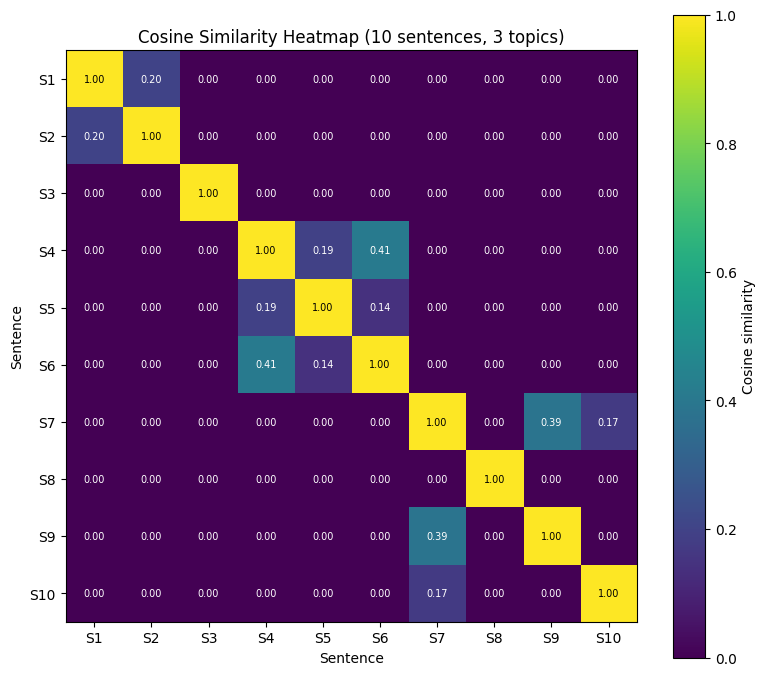

S1 - The dog barked at the mailman
S2 - A puppy is a young dog that loves to play
S3 - Cats and dogs are popular pets
S4 - The airplane landed at the airport
S5 - Pilots fly the airplane across the ocean
S6 - The airport was busy with flights and airplane traffic
S7 - She cooked pasta with tomato sauce
S8 - Bake the bread in a hot oven
S9 - The chef cooked a delicious tomato soup
S10 - Cooking pasta takes ten minutes in boiling water


In [5]:
labels = [f"S{i+1}" for i in range(len(corpus))]
fig, ax = plt.subplots(figsize=(8,7))
im = ax.imshow(sim, cmap='viridis', vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(labels); ax.set_yticklabels(labels)
for i in range(10):
    for j in range(10):
        ax.text(j,i,f"{sim[i,j]:.2f}",ha='center',va='center',color='white' if sim[i,j]<0.6 else 'black',fontsize=7)
ax.set_title("Cosine Similarity Heatmap (10 sentences, 3 topics)")
ax.set_xlabel("Sentence"); ax.set_ylabel("Sentence")
plt.colorbar(im, label="Cosine similarity"); plt.tight_layout()
plt.savefig("day9_heatmap.png", dpi=150); plt.show()
for i,s in enumerate(corpus): print(labels[i], "-", s)

## Cosine similarity: angle vs distance
For vectors **a** and **b**:

cos(θ) = (a · b) / (‖a‖ ‖b‖)

It measures the **angle** between vectors, ignoring their length. Euclidean distance measures the straight-line gap, which depends heavily on magnitude.

**Why it matters for text:** a long document repeats words, so its vector is longer than a short one on the same topic. Euclidean distance would call them far apart just because of length. Cosine looks only at direction (the *mix* of words), so a 5-word and a 500-word text about dogs still come out as similar. Scores range 0 (no shared terms/orthogonal) to 1 (same direction) for non-negative TF-IDF vectors.

In [6]:
# Demo: same direction, different length
a = np.array([1,2,0]); b = 10*a
print("Euclidean distance:", np.linalg.norm(a-b))
print("Cosine similarity :", a@b/(np.linalg.norm(a)*np.linalg.norm(b)))

Euclidean distance: 20.12461179749811
Cosine similarity : 0.9999999999999999
